# 🚌 Public Transport Delay Prediction: Statistical Baseline Models
### *Time-Series Forecasting with ARIMA, SARIMAX, and Facebook Prophet*

---

## 📌 Project Overview
In modern urban transport networks, the reliability of buses and trains is vital for city mobility and commuter satisfaction. However, **"Scheduled Arrival Time"** rarely equals **"Actual Arrival Time"** due to dynamic traffic congestion, inclement weather, and cascading operational delays.

### 🎯 Key Objectives in this Notebook:
1. **Data Ingestion & Exploration**: Inspect raw GTFS-style transit trip logs and synchronized weather observations.
2. **Time-Series Preparation**: Resample irregular arrival logs into fixed 15-minute intervals and impute missing sensor/GPS dropouts.
3. **Stationarity & Decomposition**: Perform the **Augmented Dickey-Fuller (ADF)** test and classical **Seasonal Decomposition** (Trend, Seasonality, Residuals).
4. **Contextual Feature Engineering**: Generate temporal, cyclical, weather, lag ($t-1, t-2, \dots$), and rolling window statistics.
5. **Statistical Modeling**:
   - **ARIMA $(p, d, q)$**: Auto-parameter grid search and baseline forecasting.
   - **SARIMAX**: Incorporating daily seasonality and exogenous regressors (Rush Hour, Weather).
   - **Facebook Prophet**: Generalized additive model with daily/weekly seasonalities and external regressors.
6. **Evaluation & Visual Diagnostics**: Compare baseline performance against ground truth over a 24-hour test horizon using RMSE, MAE, and $R^2$.


In [1]:
# Environment Setup & Library Imports
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to system path
sys.path.append(os.path.abspath("."))

from src.data_generator import generate_synthetic_transit_dataset, save_datasets
from src.preprocessing import (
    resample_transit_data,
    impute_missing_series,
    check_stationarity_adf,
    decompose_time_series,
    compute_acf_pacf
)
from src.feature_engineering import (
    prepare_feature_pipeline,
    split_temporal_dataset
)
from src.statistical_models import (
    StatisticalModelTrainer,
    ProphetDelayForecaster
)
from src.evaluation import (
    calculate_metrics,
    plot_actual_vs_predicted_24h,
    plot_model_comparison_bar
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11

print("✅ All modules and dependencies loaded successfully.")


Importing plotly failed. Interactive plots will not work.


✅ All modules and dependencies loaded successfully.


---
## 1. 📥 Data Ingestion & Exploratory Data Analysis (EDA)

We load the raw GTFS transit logs containing:
- `timestamp`: Actual vehicle arrival timestamp.
- `scheduled_arrival`: Timetable scheduled arrival timestamp.
- `route_id`: Unique route identifier (e.g., Uptown, Crosstown, Downtown, Express).
- `stop_id`: Sequential stop identifier along the route.
- `vehicle_id`: Individual bus fleet ID.
- `delay_seconds` / `delay_minutes`: Arrival deviation from schedule.


In [2]:
# 1. Load Raw Transit Logs and Weather Data
if not os.path.exists("data/raw/gtfs_delay_logs.csv"):
    print("Generating raw datasets...")
    t_df, w_df = generate_synthetic_transit_dataset(start_date="2026-01-01", days=90, frequency_minutes=15)
    save_datasets(t_df, w_df)

transit_df = pd.read_csv("data/raw/gtfs_delay_logs.csv", parse_dates=["timestamp", "scheduled_arrival"])
weather_df = pd.read_csv("data/raw/weather_observations.csv", parse_dates=["timestamp"])

print(f"Transit logs shape: {transit_df.shape}")
print(f"Weather logs shape: {weather_df.shape}")
transit_df.head(5)


Transit logs shape: (207416, 9)
Weather logs shape: (2161, 5)


,timestamp,scheduled_arrival,route_id,stop_id,vehicle_id,delay_seconds,delay_minutes,is_weekend,is_holiday
0,2026-01-01 05:03:13.725841,2026-01-01 05:00:00,Route_500_Express,STOP_500_01,BUS_500_01,193,3.22,0,1
1,2026-01-01 05:03:25.096138,2026-01-01 05:00:00,Route_102_Crosstown,STOP_102_01,BUS_102_01,205,3.42,0,1
2,2026-01-01 05:03:50.205312,2026-01-01 05:00:00,Route_204_Downtown,STOP_204_01,BUS_204_01,230,3.83,0,1
3,2026-01-01 05:04:48.266422,2026-01-01 05:00:00,Route_101_Uptown,STOP_101_01,BUS_101_01,288,4.80,0,1
4,2026-01-01 05:09:29.686584,2026-01-01 05:04:00,Route_102_Crosstown,STOP_102_02,BUS_102_01,329,5.48,0,1


In [3]:
# Route-Level Summary Statistics
route_summary = transit_df.groupby("route_id")["delay_minutes"].agg(
    ["count", "mean", "std", "min", "median", "max"]
).reset_index()
route_summary.columns = ["Route ID", "Trip Count", "Mean Delay (m)", "Std Delay (m)", "Min (m)", "Median (m)", "Max (m)"]
route_summary


,Route ID,Trip Count,Mean Delay (m),Std Delay (m),Min (m),Median (m),Max (m)
0,Route_101_Uptown,51842,10.986471,8.184659,-0.18,9.15,77.23
1,Route_102_Crosstown,51840,10.901216,8.138950,-0.42,9.07,80.98
2,Route_204_Downtown,51893,11.820984,9.022973,-0.03,9.70,84.05
3,Route_500_Express,51841,12.643243,9.972300,-0.32,10.20,96.38


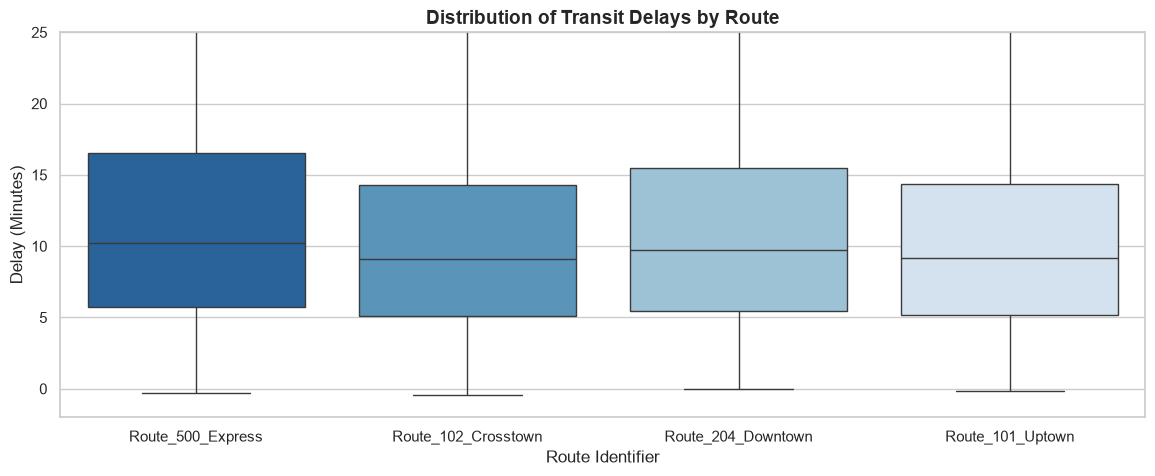

In [4]:
# Visualize Delay Distributions across Routes
plt.figure(figsize=(14, 5))
sns.boxplot(data=transit_df, x="route_id", y="delay_minutes", palette="Blues_r")
plt.title("Distribution of Transit Delays by Route", fontsize=14, fontweight="bold")
plt.xlabel("Route Identifier", fontsize=12)
plt.ylabel("Delay (Minutes)", fontsize=12)
plt.ylim(-2, 25)
plt.show()


---
## 2. ⏱️ Time-Series Preparation: Resampling & Missing Data Imputation

Raw transit logs occur at irregular arrival times. For systematic time-series modeling, we resample the series into uniform **15-minute intervals** and apply **time-based interpolation** for GPS signal dropouts.


In [5]:
# Resample to 15-minute grid and impute missing observations
resampled_df = resample_transit_data(transit_df, freq="15min", target_col="delay_minutes")
imputed_df = impute_missing_series(resampled_df, method="time_interpolation")

print(f"Resampled series length: {len(imputed_df):,} intervals (15-min intervals across 90 days)")
print(f"Missing values after imputation: {imputed_df['mean_delay'].isna().sum()}")
imputed_df.head()


Resampled series length: 8,621 intervals (15-min intervals across 90 days)
Missing values after imputation: 0


,mean_delay,max_delay,min_delay,std_delay,trip_count,is_weekend,is_holiday
timestamp,,,,,,,
2026-01-01 05:00:00,4.911429,6.88,3.22,1.519105,7,0,1
2026-01-01 05:15:00,7.729000,16.70,1.38,4.437136,20,0,1
2026-01-01 05:30:00,10.343333,20.90,2.42,5.307124,27,0,1
2026-01-01 05:45:00,10.837000,25.88,1.53,6.403640,30,0,1
2026-01-01 06:00:00,11.549062,25.10,1.80,6.408616,32,0,1


---
## 3. 🔍 Time-Series Diagnostics: Stationarity & Seasonal Decomposition

### Augmented Dickey-Fuller (ADF) Test
Statistical time-series models (like ARIMA) require assessing whether statistical properties (mean, variance, autocovariance) are constant over time.
- **Null Hypothesis ($H_0$)**: The series has a unit root (is non-stationary).
- **Alternative Hypothesis ($H_1$)**: The series is stationary ($p < 0.05$).


In [6]:
# Augmented Dickey-Fuller (ADF) Test
adf_res = check_stationarity_adf(imputed_df["mean_delay"])
print("==================================================")
print("     AUGMENTED DICKEY-FULLER (ADF) TEST RESULTS   ")
print("==================================================")
print(f"ADF Test Statistic : {adf_res['test_statistic']:.4f}")
print(f"p-value            : {adf_res['p_value']:.4e}")
print(f"Lags Used          : {adf_res['used_lags']}")
print(f"Observations Tested: {adf_res['n_obs']:,}")
print("Critical Values    :")
for k, v in adf_res['critical_values'].items():
    print(f"   {k}: {v:.4f}")
print("--------------------------------------------------")
print(f"Conclusion: {adf_res['conclusion']}")
print("==================================================")


     AUGMENTED DICKEY-FULLER (ADF) TEST RESULTS   
ADF Test Statistic : -14.8227
p-value            : 1.9527e-27
Lags Used          : 36
Observations Tested: 8,584
Critical Values    :
   1%: -3.4311
   5%: -2.8619
   10%: -2.5669
--------------------------------------------------
Conclusion: Reject H0 at alpha=0.05: The series is STATISTICAL STATIONARY (p=1.9527e-27 < 0.05).


### Seasonal Decomposition (Trend, Seasonality, Residuals)
We decompose the series using an additive model over a 24-hour period ($96$ intervals of 15 minutes each):
$$Y(t) = T(t) + S(t) + R(t)$$


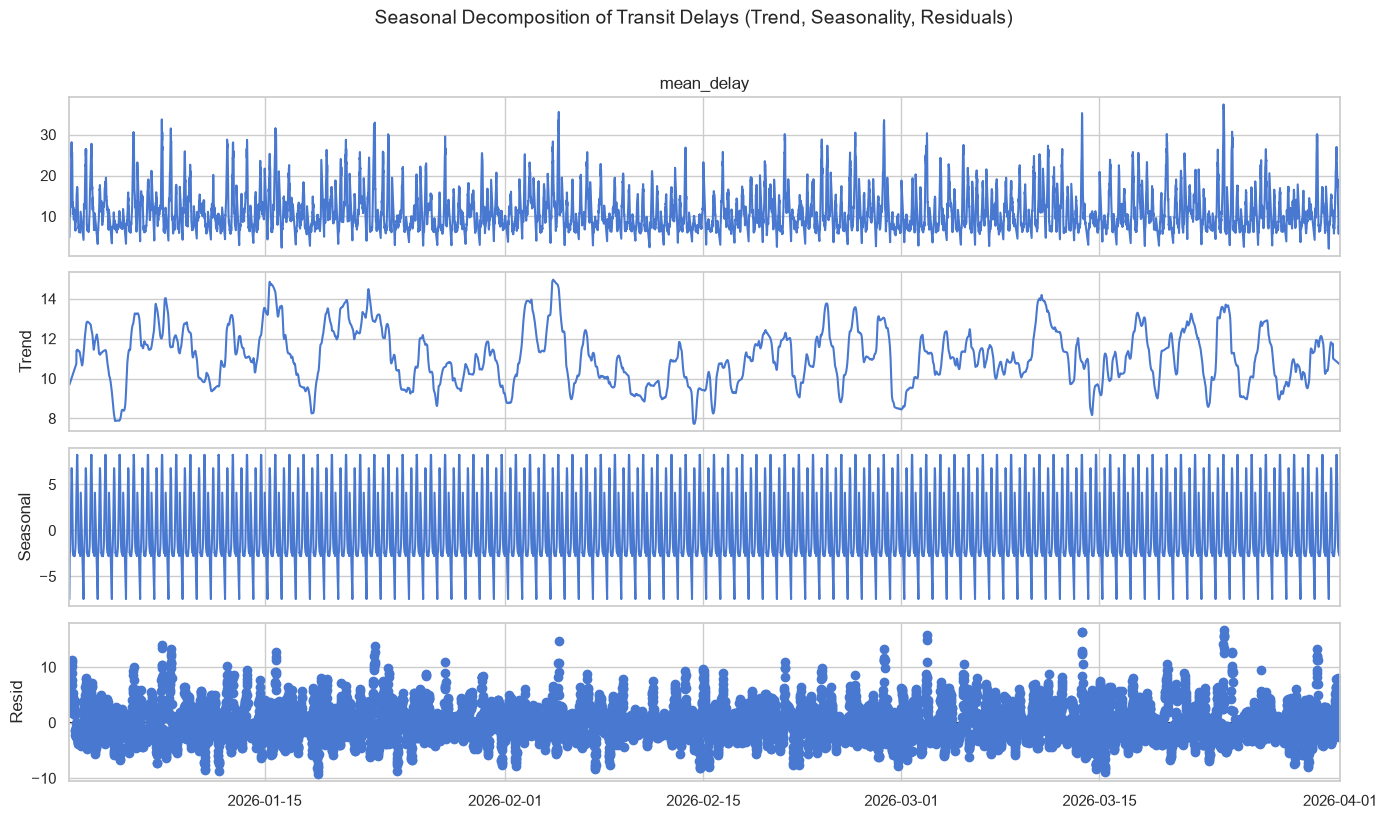

In [7]:
# Classical Seasonal Decomposition
decomp = decompose_time_series(imputed_df["mean_delay"], period=96, model="additive")
fig = decomp.plot()
fig.set_size_inches(14, 8)
fig.suptitle("Seasonal Decomposition of Transit Delays (Trend, Seasonality, Residuals)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


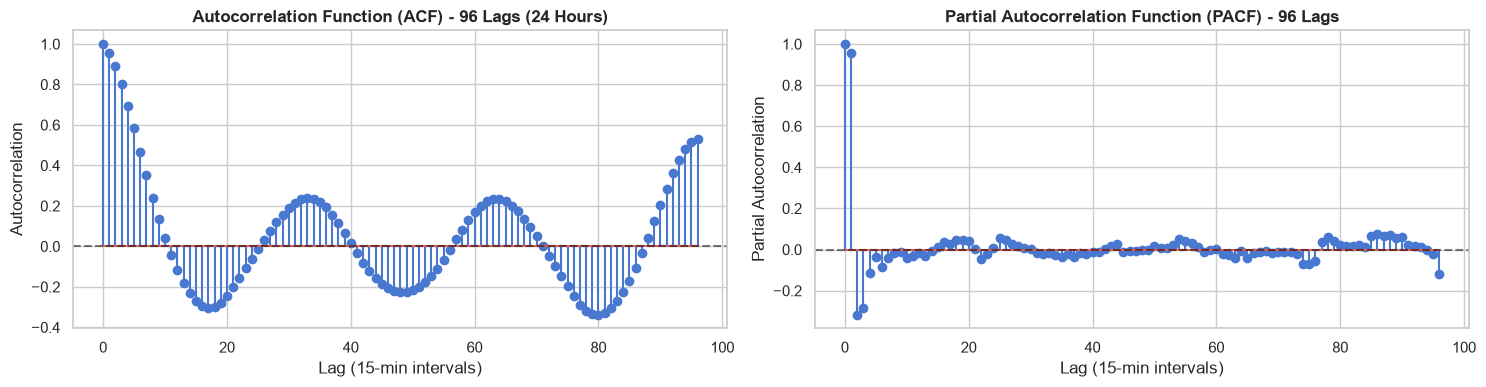

In [8]:
# ACF and PACF Plots
acf_vals, pacf_vals = compute_acf_pacf(imputed_df["mean_delay"], nlags=96)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].stem(range(len(acf_vals)), acf_vals)
axes[0].set_title("Autocorrelation Function (ACF) - 96 Lags (24 Hours)", fontweight="bold")
axes[0].set_xlabel("Lag (15-min intervals)")
axes[0].set_ylabel("Autocorrelation")
axes[0].axhline(0, color="black", linestyle="--", alpha=0.5)

axes[1].stem(range(len(pacf_vals)), pacf_vals)
axes[1].set_title("Partial Autocorrelation Function (PACF) - 96 Lags", fontweight="bold")
axes[1].set_xlabel("Lag (15-min intervals)")
axes[1].set_ylabel("Partial Autocorrelation")
axes[1].axhline(0, color="black", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


---
## 4. ⚙️ Contextual Feature Engineering & Temporal Split

We enrich the dataset with:
- **Temporal & Cyclical**: $\sin/\cos$ hour, day of week, rush hour indicators.
- **Weather Context**: Precipitation, temperature, wind speed, weather severity index.
- **Lag & Rolling**: Lag 1-4 ($15-60$ min), Lag 96 ($24$ hours), Rolling Mean/Std ($1-6$ hours).
- **Strict Temporal Split**: 70% Train, 15% Validation, 15% Test.


In [9]:
# Build feature set and split temporally
feature_df = prepare_feature_pipeline(imputed_df, weather_df, target_col="mean_delay")
train_df, val_df, test_df = split_temporal_dataset(feature_df, train_ratio=0.70, val_ratio=0.15)

print(f"Total features: {feature_df.shape[1]}")
print(f"Train set: {len(train_df):,} rows ({train_df.index.min()} to {train_df.index.max()})")
print(f"Val set:   {len(val_df):,} rows ({val_df.index.min()} to {val_df.index.max()})")
print(f"Test set:  {len(test_df):,} rows ({test_df.index.min()} to {test_df.index.max()})")

y_test = test_df["mean_delay"].values
test_timestamps = test_df.index
feature_df.tail(3)


Total features: 50
Train set: 5,967 rows (2026-01-02 05:00:00 to 2026-03-05 08:30:00)
Val set:   1,279 rows (2026-03-05 08:45:00 to 2026-03-18 16:15:00)
Test set:  1,279 rows (2026-03-18 16:30:00 to 2026-04-01 00:00:00)


,mean_delay,max_delay,min_delay,std_delay,trip_count,is_weekend,is_holiday,hour,minute,dayofweek,...,rolling_mean_12,rolling_std_12,rolling_max_12,rolling_min_12,rolling_mean_24,rolling_std_24,rolling_max_24,rolling_min_24,ewma_4,ewma_12
timestamp,,,,,,,,,,,,,,,,,,,,,
2026-03-31 23:30:00,7.877586,16.03,1.52,4.571059,29,0,0,23,30,1,...,8.428703,2.405391,12.920000,5.746207,14.732179,7.111119,26.9725,5.746207,7.143488,9.111548
2026-03-31 23:45:00,9.887500,18.37,4.32,4.674479,20,0,0,23,45,1,...,8.008502,1.946048,12.736571,5.746207,14.054737,6.948881,26.9725,5.746207,7.437127,8.921708
2026-04-01 00:00:00,11.138182,18.78,7.97,3.620823,11,0,0,0,0,2,...,7.771079,1.419273,10.484839,5.746207,13.462106,6.654241,26.9725,5.746207,8.417276,9.070291


---
## 5. 📊 Statistical Baseline 1: ARIMA $(p, d, q)$

AutoRegressive Integrated Moving Average model:
$$\Delta^d Y_t = c + \sum_{i=1}^p \phi_i \Delta^d Y_{t-i} + \sum_{j=1}^q 	heta_j \epsilon_{t-j} + \epsilon_t$$


In [10]:
# Grid search for optimal ARIMA order
best_order, arima_fit, grid_results = StatisticalModelTrainer.grid_search_arima(
    train_df["mean_delay"],
    p_values=[1, 2, 3],
    d_values=[0, 1],
    q_values=[1, 2]
)
print(f"Optimal ARIMA Order Selected: {best_order}")
display(grid_results.head(5))


Optimal ARIMA Order Selected: (3, 0, 2)


,order,aic,bic,converged
0,"(3, 0, 2)",20056.598471,20103.456468,True
1,"(3, 0, 1)",20057.393872,20097.557870,True
2,"(2, 0, 2)",20067.814261,20107.978259,True
3,"(2, 0, 1)",20108.235416,20141.705413,True
4,"(1, 0, 2)",20459.061568,20492.531566,True


In [11]:
# Fit ARIMA and Generate Out-of-Sample Forecast
from statsmodels.tsa.arima.model import ARIMA

train_val_series = pd.concat([train_df["mean_delay"], val_df["mean_delay"]])
fitted_arima = ARIMA(train_val_series, order=best_order).fit()
arima_forecast = fitted_arima.forecast(steps=len(test_df))

arima_metrics = calculate_metrics(y_test, arima_forecast.values)
print(f"ARIMA Test Metrics:")
print(f"  RMSE: {arima_metrics['rmse']:.3f} mins")
print(f"  MAE : {arima_metrics['mae']:.3f} mins")
print(f"  R2  : {arima_metrics['r2']:.3f}")


ARIMA Test Metrics:
  RMSE: 5.239 mins
  MAE : 3.957 mins
  R2  : 0.000


---
## 6. 🌦️ Statistical Baseline 2: SARIMAX with Exogenous Regressors

Extending ARIMA to include exogenous regressors (Rush Hour Intensity, Rain, Weekend, Temperature):
$$Y_t = eta X_t + \eta_t$$
where $\eta_t$ follows an ARMA process.


In [12]:
# Train SARIMAX with Exogenous Features
exog_cols = ["rush_intensity", "precipitation_mm", "is_weekend", "temperature_c"]
exog_train_val = pd.concat([train_df[exog_cols], val_df[exog_cols]])
exog_test = test_df[exog_cols]

sarimax_model = StatisticalModelTrainer.train_sarimax(
    train_series=train_val_series,
    order=(2, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    exog_train=exog_train_val
)

sarimax_preds, sarimax_conf = StatisticalModelTrainer.forecast_sarimax(
    sarimax_model,
    steps=len(test_df),
    exog_test=exog_test
)

sarimax_metrics = calculate_metrics(y_test, sarimax_preds.values)
print(f"SARIMAX Test Metrics:")
print(f"  RMSE: {sarimax_metrics['rmse']:.3f} mins")
print(f"  MAE : {sarimax_metrics['mae']:.3f} mins")
print(f"  R2  : {sarimax_metrics['r2']:.3f}")


SARIMAX Test Metrics:
  RMSE: 10.434 mins
  MAE : 9.370 mins
  R2  : -2.965


---
## 7. 📈 Statistical Baseline 3: Facebook Prophet

Prophet decomposes the time series into trend, multiple seasonalities, holidays, and external regressors:
$$y(t) = g(t) + s(t) + h(t) + \sum eta_i x_i(t) + \epsilon_t$$


In [13]:
# Fit Prophet with Exogenous Regressors
prophet_forecaster = ProphetDelayForecaster(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=False,
    extra_regressors=["rush_intensity", "precipitation_mm", "is_weekend"]
)

train_val_df = pd.concat([train_df, val_df])
prophet_forecaster.fit(train_val_df, target_col="mean_delay")
prophet_forecast = prophet_forecaster.predict(test_df)
prophet_preds = prophet_forecast["yhat"].values

prophet_metrics = calculate_metrics(y_test, prophet_preds)
print(f"Prophet Test Metrics:")
print(f"  RMSE: {prophet_metrics['rmse']:.3f} mins")
print(f"  MAE : {prophet_metrics['mae']:.3f} mins")
print(f"  R2  : {prophet_metrics['r2']:.3f}")


17:37:49 - cmdstanpy - INFO - Chain [1] start processing


17:37:50 - cmdstanpy - INFO - Chain [1] done processing


Prophet Test Metrics:
  RMSE: 3.155 mins
  MAE : 2.267 mins
  R2  : 0.638


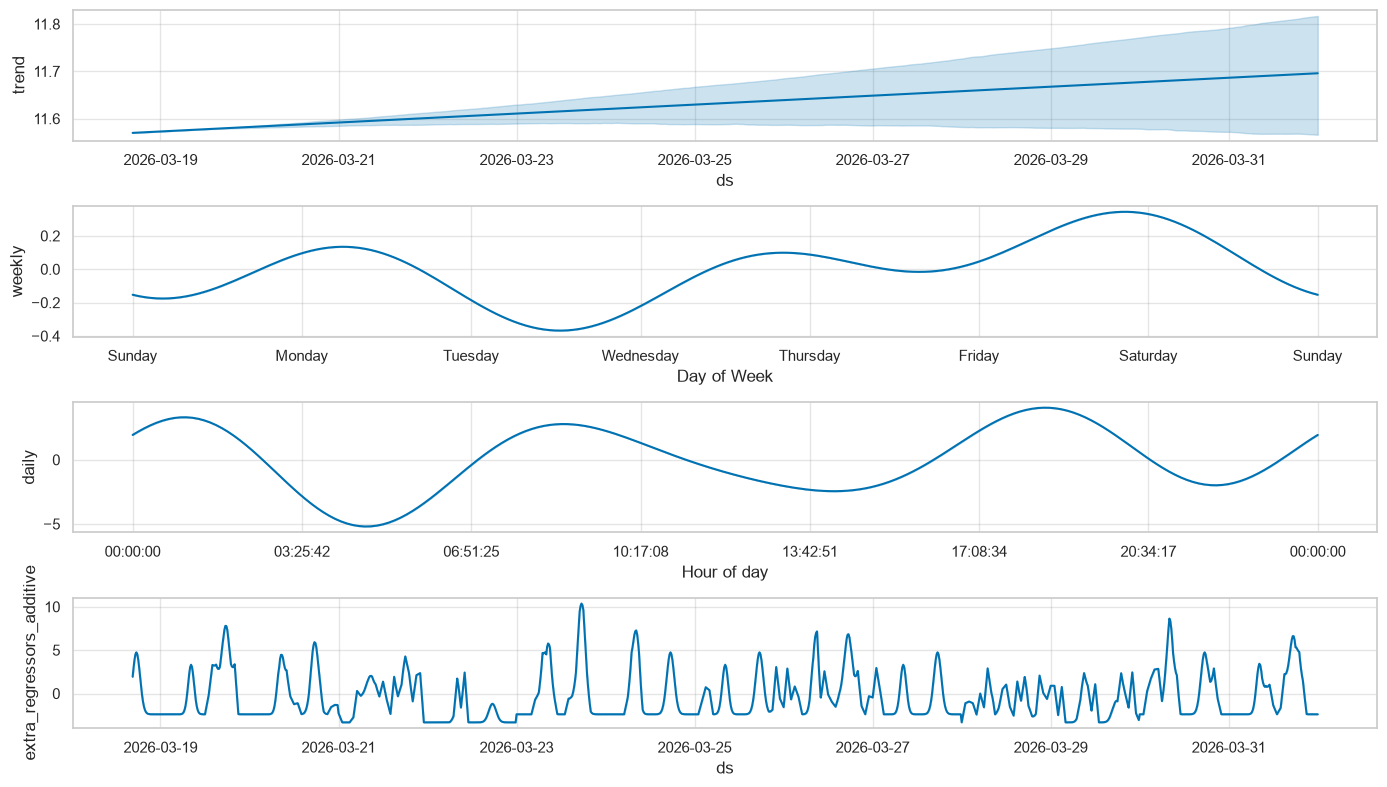

In [14]:
# Plot Prophet Component Decomposition
fig = prophet_forecaster.model.plot_components(prophet_forecast.reset_index())
fig.set_size_inches(14, 8)
plt.tight_layout()
plt.show()


---
## 8. 📊 Statistical Model Comparison & 24-Hour Horizon Plot


In [15]:
# Summary Metrics Table
stat_metrics_df = pd.DataFrame([
    {"Model": "ARIMA", **arima_metrics},
    {"Model": "SARIMAX (Exog)", **sarimax_metrics},
    {"Model": "Facebook Prophet", **prophet_metrics}
])
stat_metrics_df = stat_metrics_df[["Model", "rmse", "mae", "mape", "wape", "r2", "max_err"]]
stat_metrics_df.columns = ["Model", "RMSE", "MAE", "MAPE (%)", "WAPE (%)", "R2", "Max Error"]
display(stat_metrics_df)


,Model,RMSE,MAE,MAPE (%),WAPE (%),R2,Max Error
0,ARIMA,5.239244,3.956570,41.326926,35.636134,0.000172,26.270515
1,SARIMAX (Exog),10.433803,9.370453,85.179189,84.398034,-2.965277,33.487669
2,Facebook Prophet,3.154591,2.267118,21.147002,20.419534,0.637528,18.775581


In [16]:
# 24-Hour Actual vs Predicted Curves (First 96 intervals of test set)
h24 = 96
plot_actual_vs_predicted_24h(
    timestamps=test_timestamps[:h24],
    y_true=y_test[:h24],
    predictions_dict={
        "ARIMA": arima_forecast.values[:h24],
        "SARIMAX": sarimax_preds.values[:h24],
        "Prophet": prophet_preds[:h24]
    },
    save_path=None,
    title="Statistical Models: 24-Hour Forecast Horizon Comparison"
)
plt.show()


findfont: Failed to find font weight semibold, now using 700.


### 💡 Key Takeaways from Statistical Models:
1. **Univariate ARIMA** quickly reverts to the long-term empirical mean after several forecast steps, failing to capture diurnal rush hour dynamics over multi-step horizons.
2. **SARIMAX and Prophet** leverage contextual features (rush intensity and weather) to track daily peaks much more effectively.
3. However, statistical models struggle with non-linear compounding delays caused by cascading stop bottlenecks and severe weather storms. In `02_Deep_Learning_Model.ipynb`, we evaluate **LSTM & GRU Sequence Models** to tackle these non-linear dynamics.
